In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import math
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

In [9]:
!python smaparsing_indexes.py


sp500 1950-01-03 2026-10-16 19320  - duplicates: 0  - NaN cells: 0  - longest gap (in days): 7.0
/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/smaparsing_indexes.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"sma_{length}"] = df["Close"].rolling(window=length).mean() # calculates mean of rolling window of length and adds it as a new column to the dataframe
/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/smaparsing_indexes.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"sma_{le

In [2]:
original_data_path = Path.home() / "Documents" / "Github Repositories" / "SMAstrategy" / "data" / "raw"

processed_data_path = Path.home() / "Documents" / "Github Repositories" / "SMAstrategy" / "data" / "processed"

In [3]:
results_data_path = Path.home() / "Documents" / "Github Repositories" / "SMAstrategy" / "data" / "results"
results_data_path.mkdir(parents=True, exist_ok=True)

In [4]:
# sorry for excessive quotations, trying to quit lazy Ai code writing habits

In [5]:
# Indexes are only comparable between themselves, and not between each other for most cases - different starts, circumstances

In [6]:
PAYMENT = 500 # per month ( unrealistic, obviously. figurative value not accounting for inflation)
INTEREST_RATE = 0.03 # 3% interest rate for cash in the bank
START_DATE = "1986-01-01"

DIV_YIELD = {   # note: these are approximate values and may vary over time
    "sp500": 0.02, "nasdaq_comp": 0.01, "nasdaq100": 0.01, "ftse100": 0.04,
    "nikkei": 0.01, "dax": 0.0, "cac40": 0.03, "hang_seng": 0.03, "shanghai": 0.02,
    "euro_stoxx": 0.03, "nifty": 0.013, "dow_jones": 0.02,
}                                                                    


                    # dictionaries
STRATEGIES = {"DCA": None}          
for i in range(2, 201):
    STRATEGIES[f"SMA{i}"] = f"sma_{i}"

In [7]:
def simulate(df, sma_timeframe, dividend_yield, values=None): # function can receive a values argument, but it doesn't have to
    dates = df.index.tolist()
    closes = df["Close"].tolist()
    if sma_timeframe is not None:
        smas = df[sma_timeframe].tolist() # every days calculated sma in a list

    valid = df[(df.index >= START_DATE) & df["sma_200"].notna()]  # first day with sma_200 available. filtered dataframe with only "valid" rows
    start = df.index.get_loc(valid.index[0]) # first column where in valid. this will iterate for all datasets not one df with all indexes one per df
    end = df.index.get_loc(valid.index[-1])


    cash = 0
    units = 0
    units_bought = 0
    total_invested_stocks = 0
    last_sma_value_when_buying = 0
    total_invested = 0
    last_value_bought = 0
    n_buys = 0
    next_payment = dates[start].replace(day=1) + pd.DateOffset(months=1)       # next_payment = dates[start] + pd.Timedelta(days=(7 - dates[start].weekday()) % 7) for weekly simulations



    for i in range(start, end + 1):
        days = (dates[i] - dates[i - 1]).days # days between i row and i-1 row as int (.days returns int). used for interest/dividend calculations (since there are not rows for all days)
        cash = cash * (1 + INTEREST_RATE) ** (days / 365)
        units = units * (1 + dividend_yield) ** (days / 365)

        while next_payment <= dates[i]: # checks if payday has come
            cash += PAYMENT
            total_invested += PAYMENT # total invested is both cash and stock
            next_payment += pd.DateOffset(months=1) # next_payment += pd.Timedelta(days=7) for weekly simulations

        if sma_timeframe is None:
            signal = True       # if no sma_timeframe is provided, the signal is always True (DCA strategy)
        else:
            signal = closes[i - 1] < smas[i - 1] # if the previous day's close is below the previous day's sma_x, then the signal is True (buy signal)

        if cash > 0 and signal == True: # if there is cash available and the signal is True, then buy
            units = units + cash / closes[i-1]
            units_bought += cash / closes[i-1]
            total_invested_stocks += cash
            n_buys += 1
            cash = 0
            last_value_bought = closes[i-1]
            if sma_timeframe is not None:
                last_sma_value_when_buying = smas[i - 1]

        if values is not None:
            values.append(units * closes[i] + cash)   # so that we can plot the value of the portfolio over time later is not doing much here

    final_value = units * closes[-1] + cash
    keys = {
        "strategy_simulated": sma_timeframe if sma_timeframe is not None else "DCA",
        "start_date": dates[start].date(),
        "end_date": dates[-1].date(),
        "total_invested": total_invested,
        "total_invested_stocks": total_invested_stocks,
        "final_value": final_value,
        "total_return_pct": (final_value / total_invested - 1) * 100,
        "units": units,
        "avg_price": total_invested_stocks / units_bought if units_bought > 0 else None,
        "leftover_cash": cash,
        "n_buys": n_buys,
        "last_close": closes[i],
        "last_value_bought": last_value_bought,
        "last_sma_value_when_buying": last_sma_value_when_buying
    }

    return pd.DataFrame([keys], index=[keys["strategy_simulated"]]) # returns df with all those columns and index is the strategy

In [8]:
def run_index_simulator(df, name):
    results = [] # always need to maintain empty list to receive att
    for strategy, sma_timeframe in STRATEGIES.items():
        results.append(simulate(df, sma_timeframe, DIV_YIELD[name]))

        
    table = pd.concat(results)
    table.insert(0, "index", name)   # first column holds the index name
    return table

In [9]:
df = pd.read_csv(processed_data_path / "sp500_processed.csv", index_col=0, parse_dates=True)


In [10]:
run_index_simulator(df,"sp500")

,index,strategy_simulated,start_date,end_date,total_invested,total_invested_stocks,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys,last_close,last_value_bought,last_sma_value_when_buying
DCA,sp500,DCA,1986-01-02,2026-10-16,244500,244500.000000,4.101466e+06,1577.491039,535.478523,833.918779,0.000000,489,7659.439941,7651.540039,0.000000
sma_2,sp500,sma_2,1986-01-02,2026-10-16,244500,244529.605442,4.098161e+06,1576.139381,535.047055,834.625289,0.000000,489,7659.439941,7651.540039,7661.189941
sma_3,sp500,sma_3,1986-01-02,2026-10-16,244500,244544.674470,4.097695e+06,1575.949039,534.986296,834.702935,0.000000,489,7659.439941,7651.540039,7668.689941
sma_4,sp500,sma_4,1986-01-02,2026-10-16,244500,244554.925985,4.099512e+06,1576.691961,535.223447,834.349669,0.000000,488,7659.439941,7651.540039,7687.369995
sma_5,sp500,sma_5,1986-01-02,2026-10-16,244500,244569.635935,4.100654e+06,1577.158926,535.372508,834.129549,0.000000,486,7659.439941,7651.540039,7690.721973
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sma_196,sp500,sma_196,1986-01-02,2026-10-16,244500,244333.825181,4.038881e+06,1551.893930,526.912995,841.983591,3022.217252,177,7659.439941,6528.520020,6652.030346
sma_197,sp500,sma_197,1986-01-02,2026-10-16,244500,244341.798624,4.039227e+06,1552.035406,526.958156,841.885062,3022.217252,176,7659.439941,6528.520020,6648.623441
sma_198,sp500,sma_198,1986-01-02,2026-10-16,244500,244437.143541,4.040463e+06,1552.540932,527.119527,841.863571,3022.217252,176,7659.439941,6528.520020,6645.260293
sma_199,sp500,sma_199,1986-01-02,2026-10-16,244500,244437.143541,4.040463e+06,1552.540932,527.119527,841.863571,3022.217252,176,7659.439941,6528.520020,6642.184161


In [11]:

pd.set_option("display.float_format", "{:,.2f}".format)   # no scientific notation, 2 decimals, thousands commas


all_tables = []
for name in DIV_YIELD:
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True)
    all_tables.append(run_index_simulator(df, name))

all_tables = pd.concat(all_tables)


display(all_tables)
all_tables.to_parquet(results_data_path / "results_full200.parquet", index=False)

,index,strategy_simulated,start_date,end_date,total_invested,total_invested_stocks,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys,last_close,last_value_bought,last_sma_value_when_buying
DCA,sp500,DCA,1986-01-02,2026-10-16,244500,"244,500.00","4,101,465.59","1,577.49",535.48,833.92,0.00,489,"7,659.44","7,651.54",0.00
sma_2,sp500,sma_2,1986-01-02,2026-10-16,244500,"244,529.61","4,098,160.79","1,576.14",535.05,834.63,0.00,489,"7,659.44","7,651.54","7,661.19"
sma_3,sp500,sma_3,1986-01-02,2026-10-16,244500,"244,544.67","4,097,695.40","1,575.95",534.99,834.70,0.00,489,"7,659.44","7,651.54","7,668.69"
sma_4,sp500,sma_4,1986-01-02,2026-10-16,244500,"244,554.93","4,099,511.85","1,576.69",535.22,834.35,0.00,488,"7,659.44","7,651.54","7,687.37"
sma_5,sp500,sma_5,1986-01-02,2026-10-16,244500,"244,569.64","4,100,653.57","1,577.16",535.37,834.13,0.00,486,"7,659.44","7,651.54","7,690.72"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sma_196,dow_jones,sma_196,1992-10-14,2026-10-16,204000,"203,065.77","1,543,225.92",656.48,29.62,"10,891.81","3,022.22",162,"52,002.41","46,341.51","46,765.01"
sma_197,dow_jones,sma_197,1992-10-14,2026-10-16,204000,"203,072.08","1,543,351.51",656.54,29.62,"10,890.91","3,022.22",162,"52,002.41","46,341.51","46,741.69"
sma_198,dow_jones,sma_198,1992-10-14,2026-10-16,204000,"203,108.66","1,542,888.57",656.32,29.61,"10,895.04","3,022.22",162,"52,002.41","46,341.51","46,718.83"
sma_199,dow_jones,sma_199,1992-10-14,2026-10-16,204000,"203,108.42","1,542,766.97",656.26,29.61,"10,895.99","3,022.22",162,"52,002.41","46,341.51","46,697.71"


In [12]:

N_BINS = 10   # number of bars in the mean charts as a variable
TOP_N = 15    # how many SMAs in the top chart

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple",
          "tab:brown", "tab:pink", "tab:gray", "tab:olive", "tab:cyan"]


finals = (
    all_tables.groupby("index")# groups by indexes, grabs only final value
    ["final_value"].apply(list)            # collects all final values and stores in a list
    .to_dict()                  # creates dictionaries
)


  # a dictionary with all indexes and final values inside for visualization purposes so sp 500 and 200 values respective of the 200 sma strats



In [13]:

names = list(DIV_YIELD)
strategy_names = list(STRATEGIES)   # # both of these create a list of the keys of these dictionaries above 


x_values = list(range(1, 201)) # would need to be updated if more smas are added
bin_size = round(len(strategy_names) / N_BINS) # round rounds if to nearest n if division was not perfect len is just 200 could just be = 200 / 10 only changes with addition of future smas n bins can change tho so not hard coded and rounded



bin_labels = [] 
for first in range(0, len(x_values), bin_size): # 0 to 200 jumping by 20 each iteration
    last = min(first + bin_size, len(x_values)) - 1  # last is first + bin size -1 so 19,39,59 and so on. len x values is (usually) 200 and to ensure it never goes over if values change ( first+ bin could surpass it)
    bin_labels.append(f"{x_values[first]}-{x_values[last]}") # 0-19, 20-39...

In [14]:


def get_bin_means(values):  # mean final amount of each bin


    means = []

    for first in range(0, len(values), bin_size): # 0, 20, 40, 60, 80, 100, 120, 140, 160, 180
        group = values[first:first + bin_size] # group = sma_index_listofvalues[1:20] creates a list with these values will create 10 lists in these intervals
        means.append(sum(group) / len(group))
    return means

In [15]:
n_rows = (len(names) + 2) // 3      # makes it 3 charts per row max in visualizations as i want to and is flexible with len names for future indexes added needs to be specified apriori



def make_grid():  # one square per index, hides the empty squares at the end
    fig, axes = plt.subplots(n_rows, 3, figsize=(18, 4 * n_rows))   # Creates a grid of plots with n_rows rows and 3 columns. Each row adds 4 inches to the figure height; the width is 18 inches.
    axes = axes.flatten()  # turns axes[0, 0]  # first plot and axes[0, 1]  # second plot into axes[0] or 1. makes axes[i] iteration easier after. figure is whole pic axes is each of the 12
    for j in range(len(names), len(axes)):
        axes[j].axis("off")   # iterates through unused axis so if i had for example 10 or 11 indexes since they go in 3s
    return axes

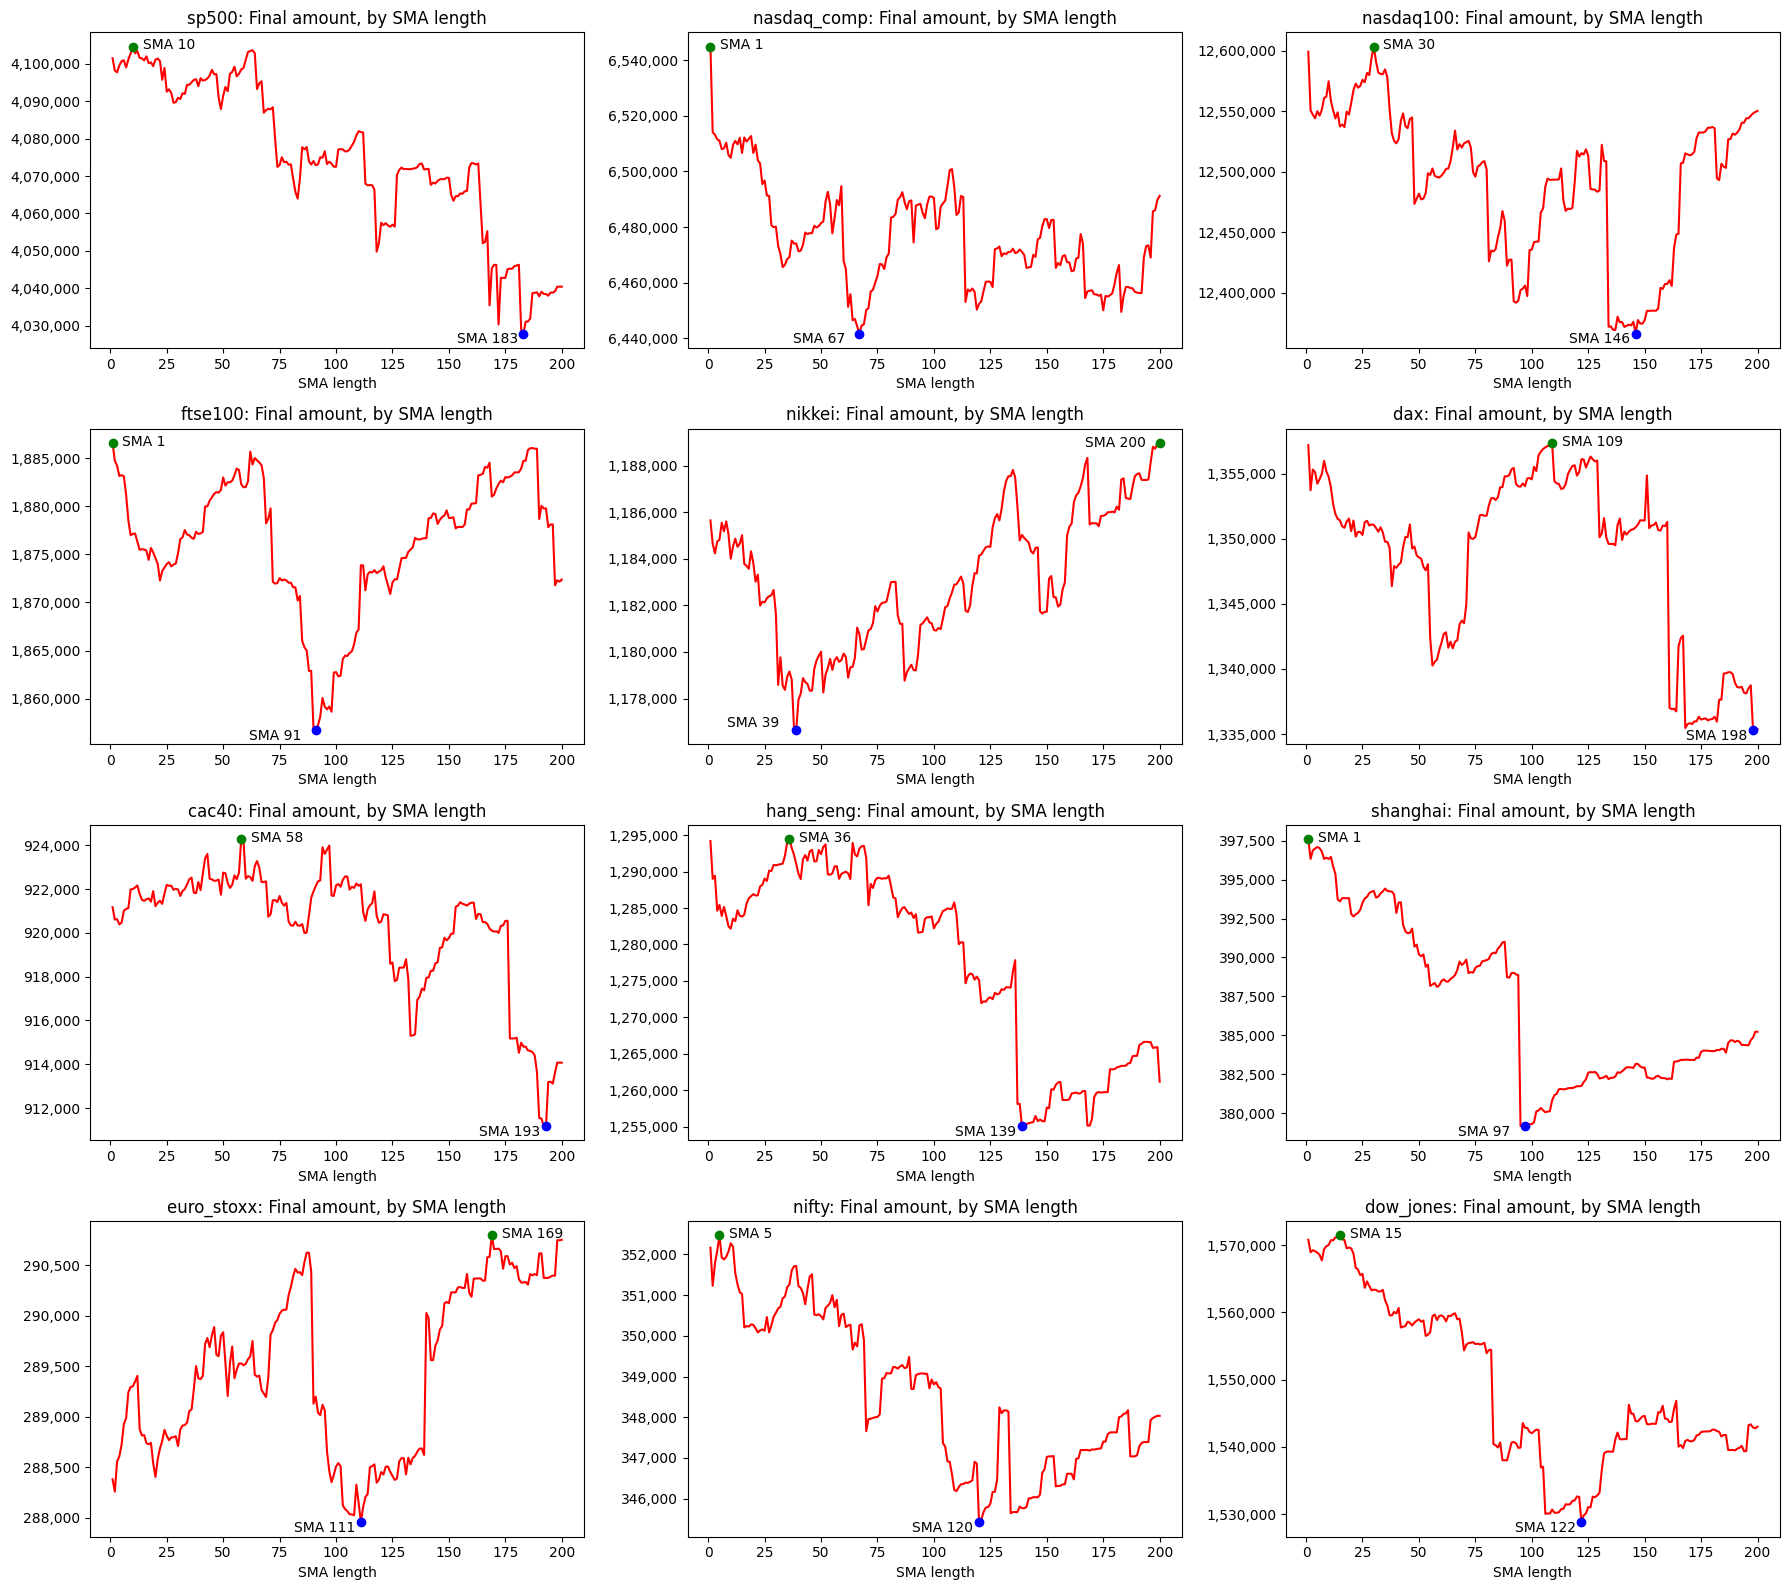

In [16]:
axes = make_grid()  # will create len(names) (12) axis no information carried yet with current settings set earlier fix column number variable n rows with number of index info transmitted as len names
for i in range(len(names)):
    ax = axes[i]  # iterates and selects each one axis and applies the settings below
    ax.plot(x_values, finals[names[i]], color="red") # sets y and x axis, x is just a list 1-200 , finals is a dict with keys=names and values from final value and i will iterate through all values for the specific index
    
    
    min_i = finals[names[i]].index(min(finals[names[i]]))  # finals[names[i]] is the iteration through all final values of an index so 200 values each iteration that is it list of 200 ints
    max_i = finals[names[i]].index(max(finals[names[i]]))  # max finds the max in the list list.index() finds its position but it only finds the first one so multiple numbers equal would need for loop
    ax.plot(x_values[min_i], finals[names[i]][min_i], "o", color="blue")
    ax.plot(x_values[max_i], finals[names[i]][max_i], "o", color="green")  # coords

    if names[i] == "nikkei":
        min_offset = (-50, 2)
        max_offset = (-54, -3)
    else:                                       # nikkei graph was a bit corrupted due to sma 200 max 
        min_offset = (-48, -7)
        max_offset = (7, -2)

    ax.annotate(   
        f"SMA {x_values[min_i]}",  # legend
        (x_values[min_i], finals[names[i]][min_i]), # coords
        xytext=min_offset,   # where to put the text relative to the point
        textcoords="offset points"        # tells Matplotlib how to interpret those numbers idk really understand these 2 lines               
    )

    ax.annotate(
        f"SMA {x_values[max_i]}",
        (x_values[max_i], finals[names[i]][max_i]),
        xytext=max_offset,
        textcoords="offset points"
    )


    ax.set_title(f"{names[i]}: Final amount, by SMA length")  # also i think ax.plot is what makes it a line chart the plot command is what carries that info
    ax.set_xlabel("SMA length")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")) # formats values in y axis to show as 4.100.ho000 and not 4e120000 or something like that
plt.tight_layout()  # auto adjuster for spacing does not hurt to have it
plt.show() # equivalent to print for plots

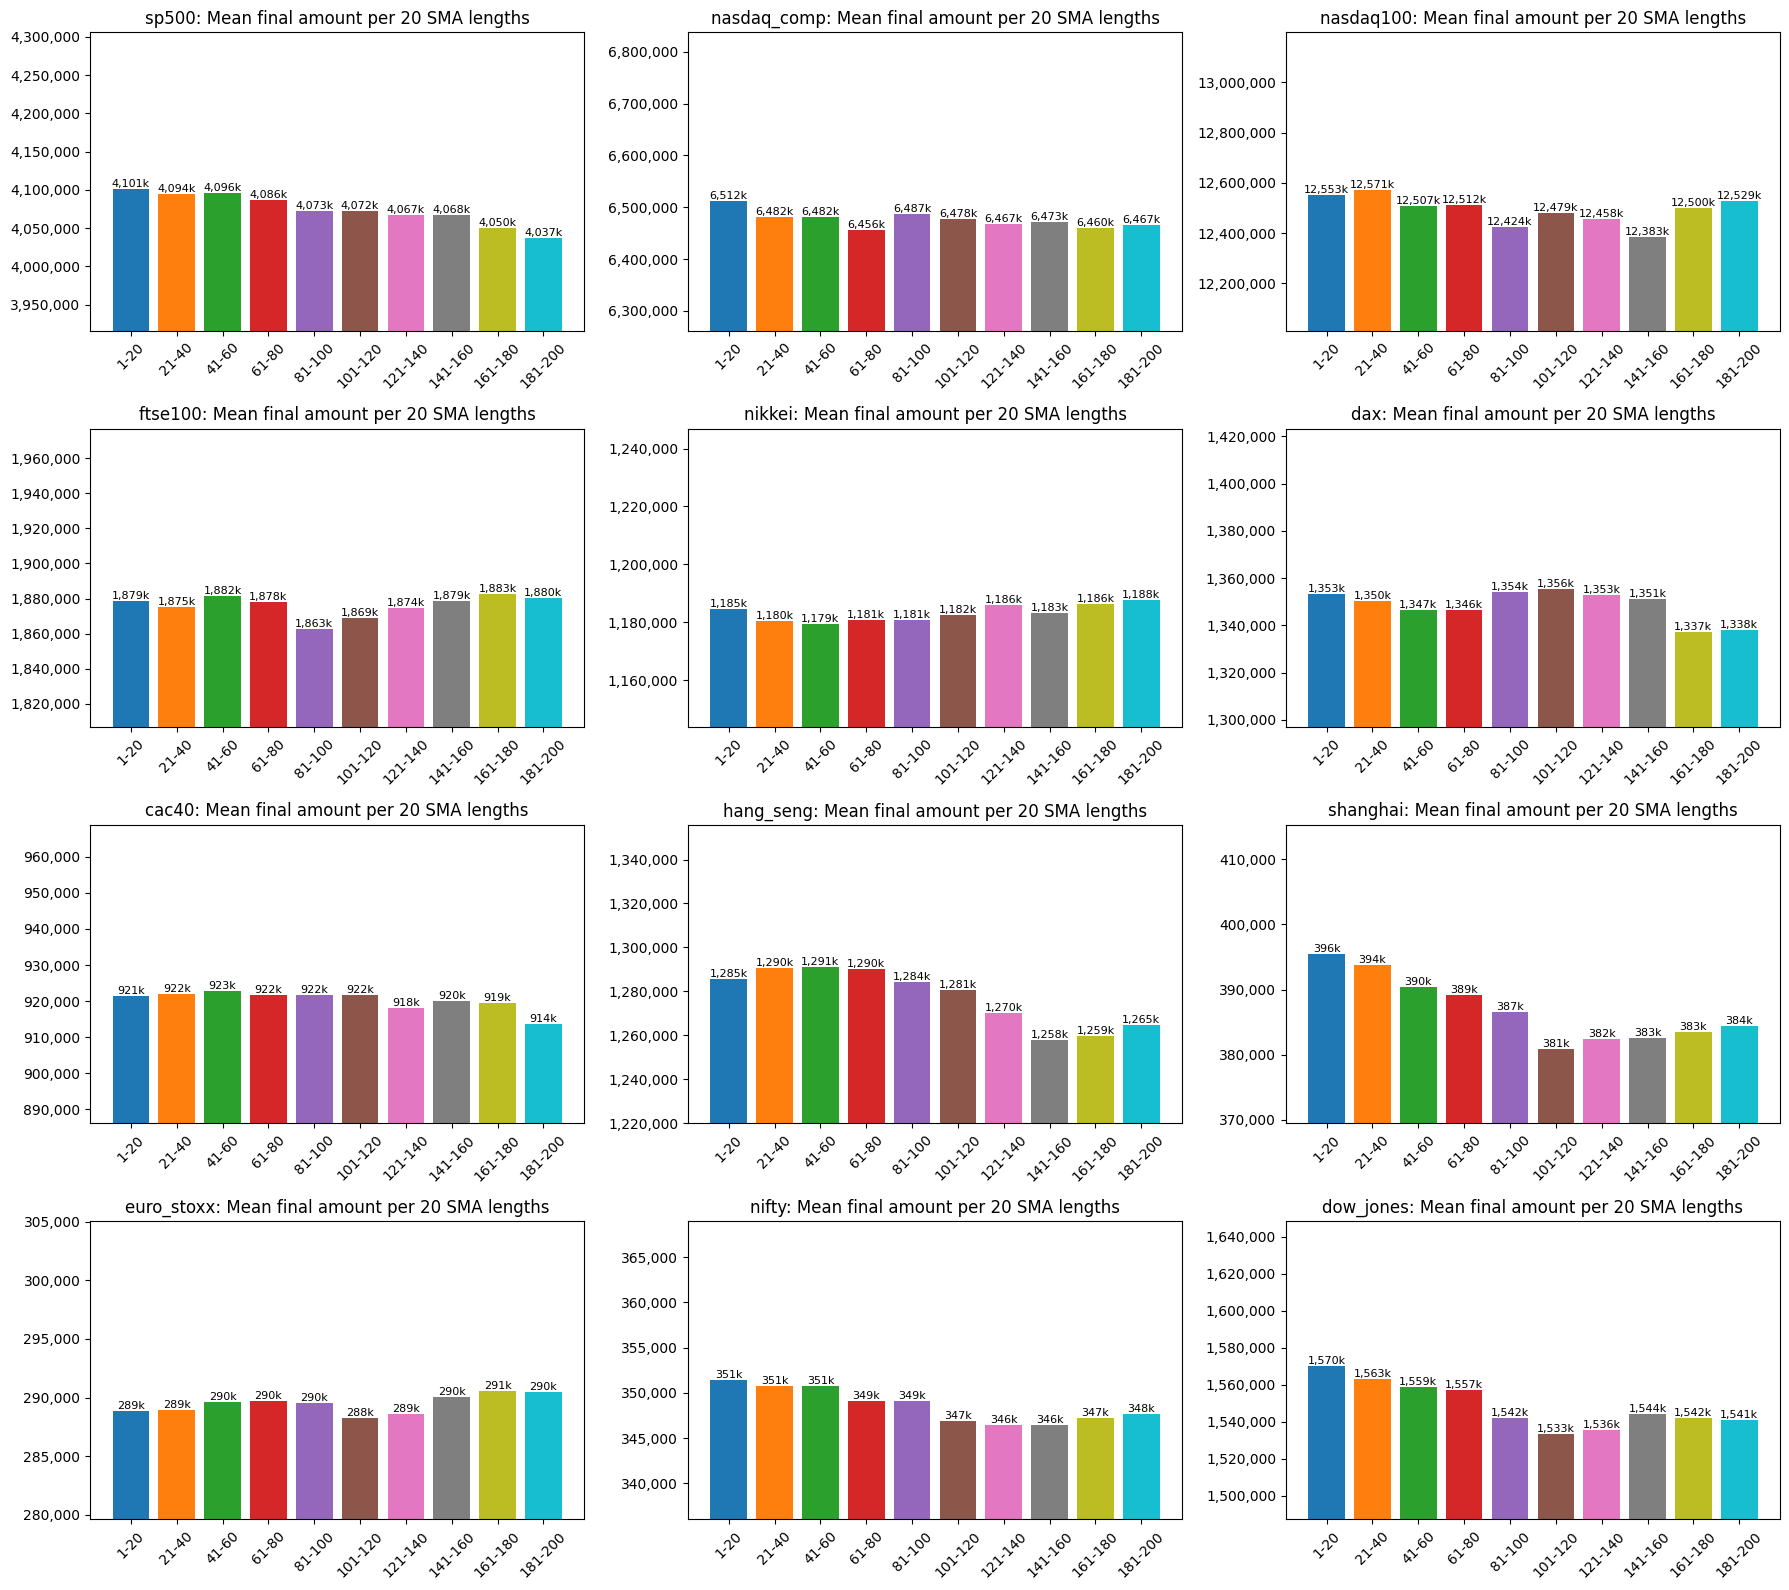

In [17]:
axes_2 = make_grid()
for i in range(len(names)):
    ax = axes_2[i]
    means = get_bin_means(finals[names[i]]) # uses the function earlier to get the means of smas by bins of the n_bins defined , means is a list
    labels = []
    for mean in means:
        labels.append(f"{mean / 1000:,.0f}k")  
    bars = ax.bar(bin_labels, means, color=colors)
    ax.bar_label(bars, labels=labels, fontsize=8)  # sets bar labels the k values above them
    ax.set_ylim(bottom=min(means) * 0.97) # starts y axis at 97% of the min of list instead of 0. no visualization insight if bars started at 0
    ax.set_title(f"{names[i]}: Mean final amount per {bin_size} SMA lengths")
    ax.tick_params(axis="x", labelrotation=45)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))  # commas and no decimal places
plt.tight_layout()
plt.show()

UFuncTypeError: ufunc 'less' did not contain a loop with signature matching types (<class 'numpy.dtypes.StrDType'>, <class 'numpy.dtypes._PyLongDType'>) -> None

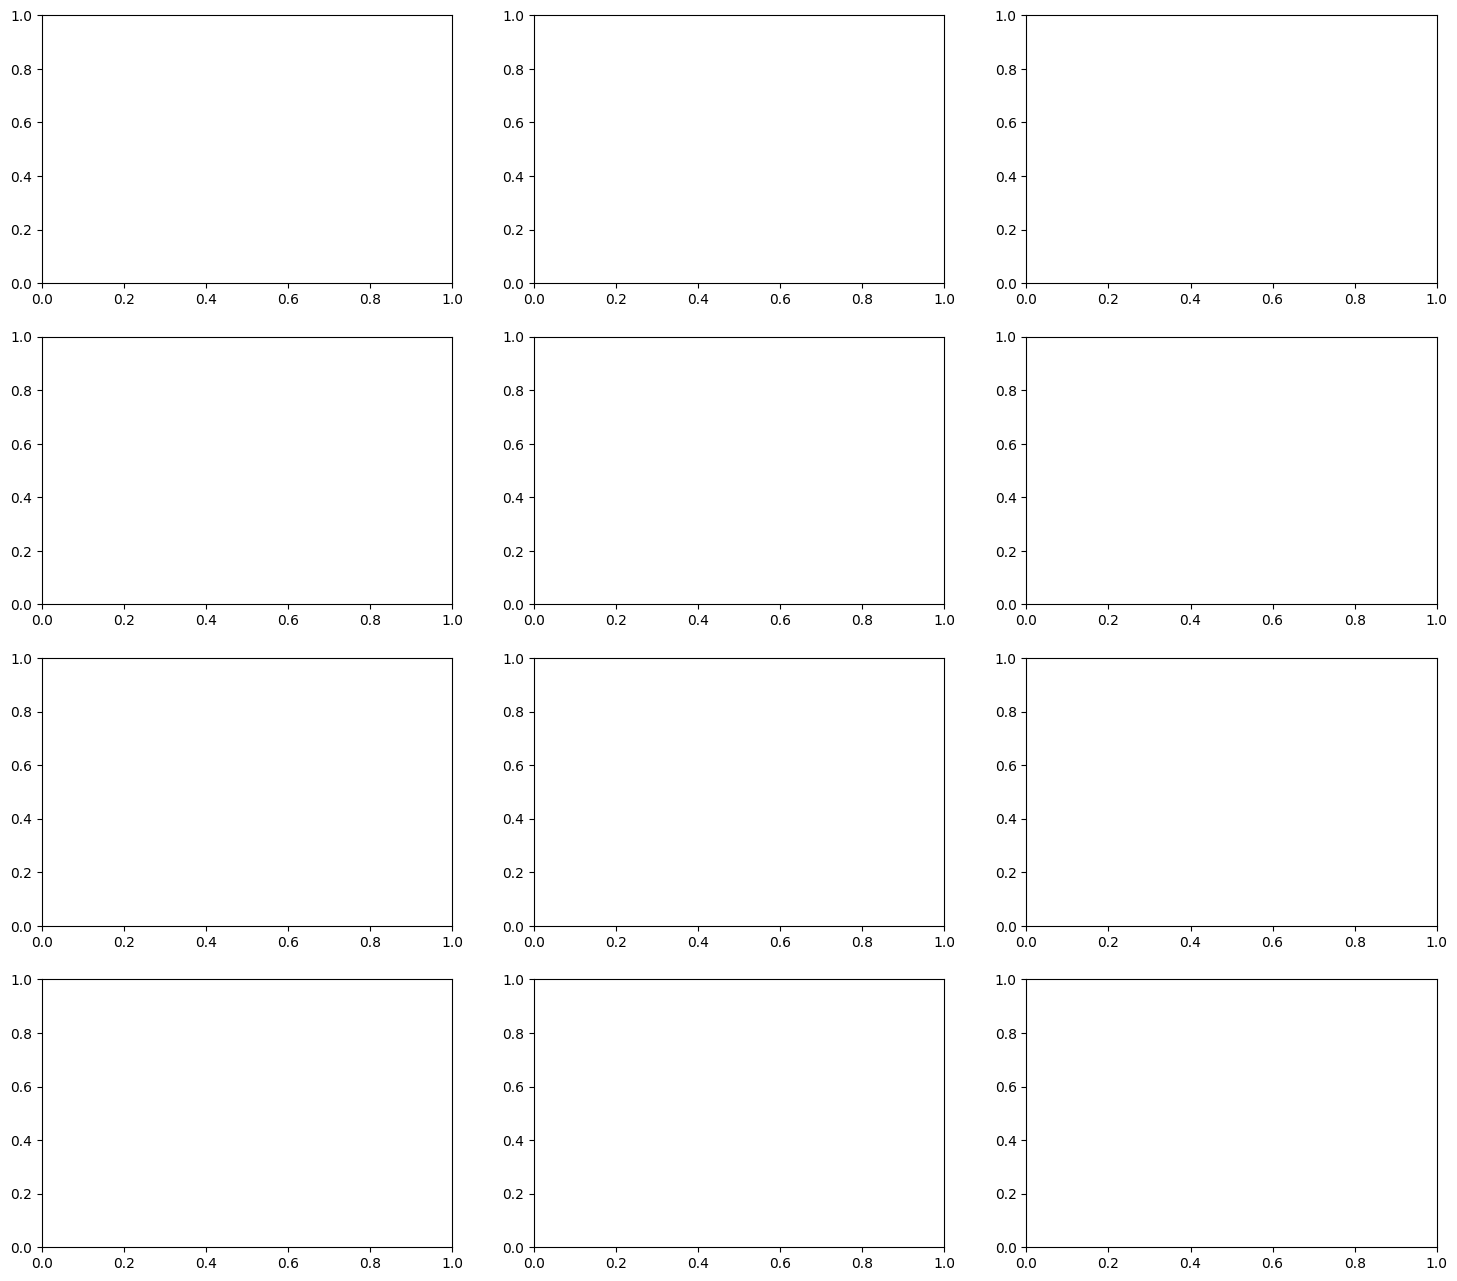

In [23]:
axes = make_grid()
for i in range(len(names)):
    ax = axes[i]
    ranking = []
    for k in range(len(strategy_names)):
        ranking.append((finals[names[i]][k], strategy_names[k]))
    ranking.sort(reverse=True)  # biggest final amount first

    top_names = []
    top_values = []
    labels = []
    for rank in range(min(TOP_N, len(ranking))):
        value, strategy = ranking[rank]
        top_names.append(strategy)
        top_values.append(value)
        labels.append(f"{value / 1000000:.2f}M")

    colors = plt.cm.RdYlGn_r(ranking)
    bars = ax.bar(top_names, top_values, color="colors")
    ax.bar_label(bars, labels=labels, rotation=90, fontsize=8, padding=2)
    ax.set_ylim(min(top_values) * 0.97, max(top_values) * 1.06)
    ax.set_title(f"{names[i]}: top {TOP_N} (DCA = sma_1)")
    ax.tick_params(axis="x", labelrotation=90)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()

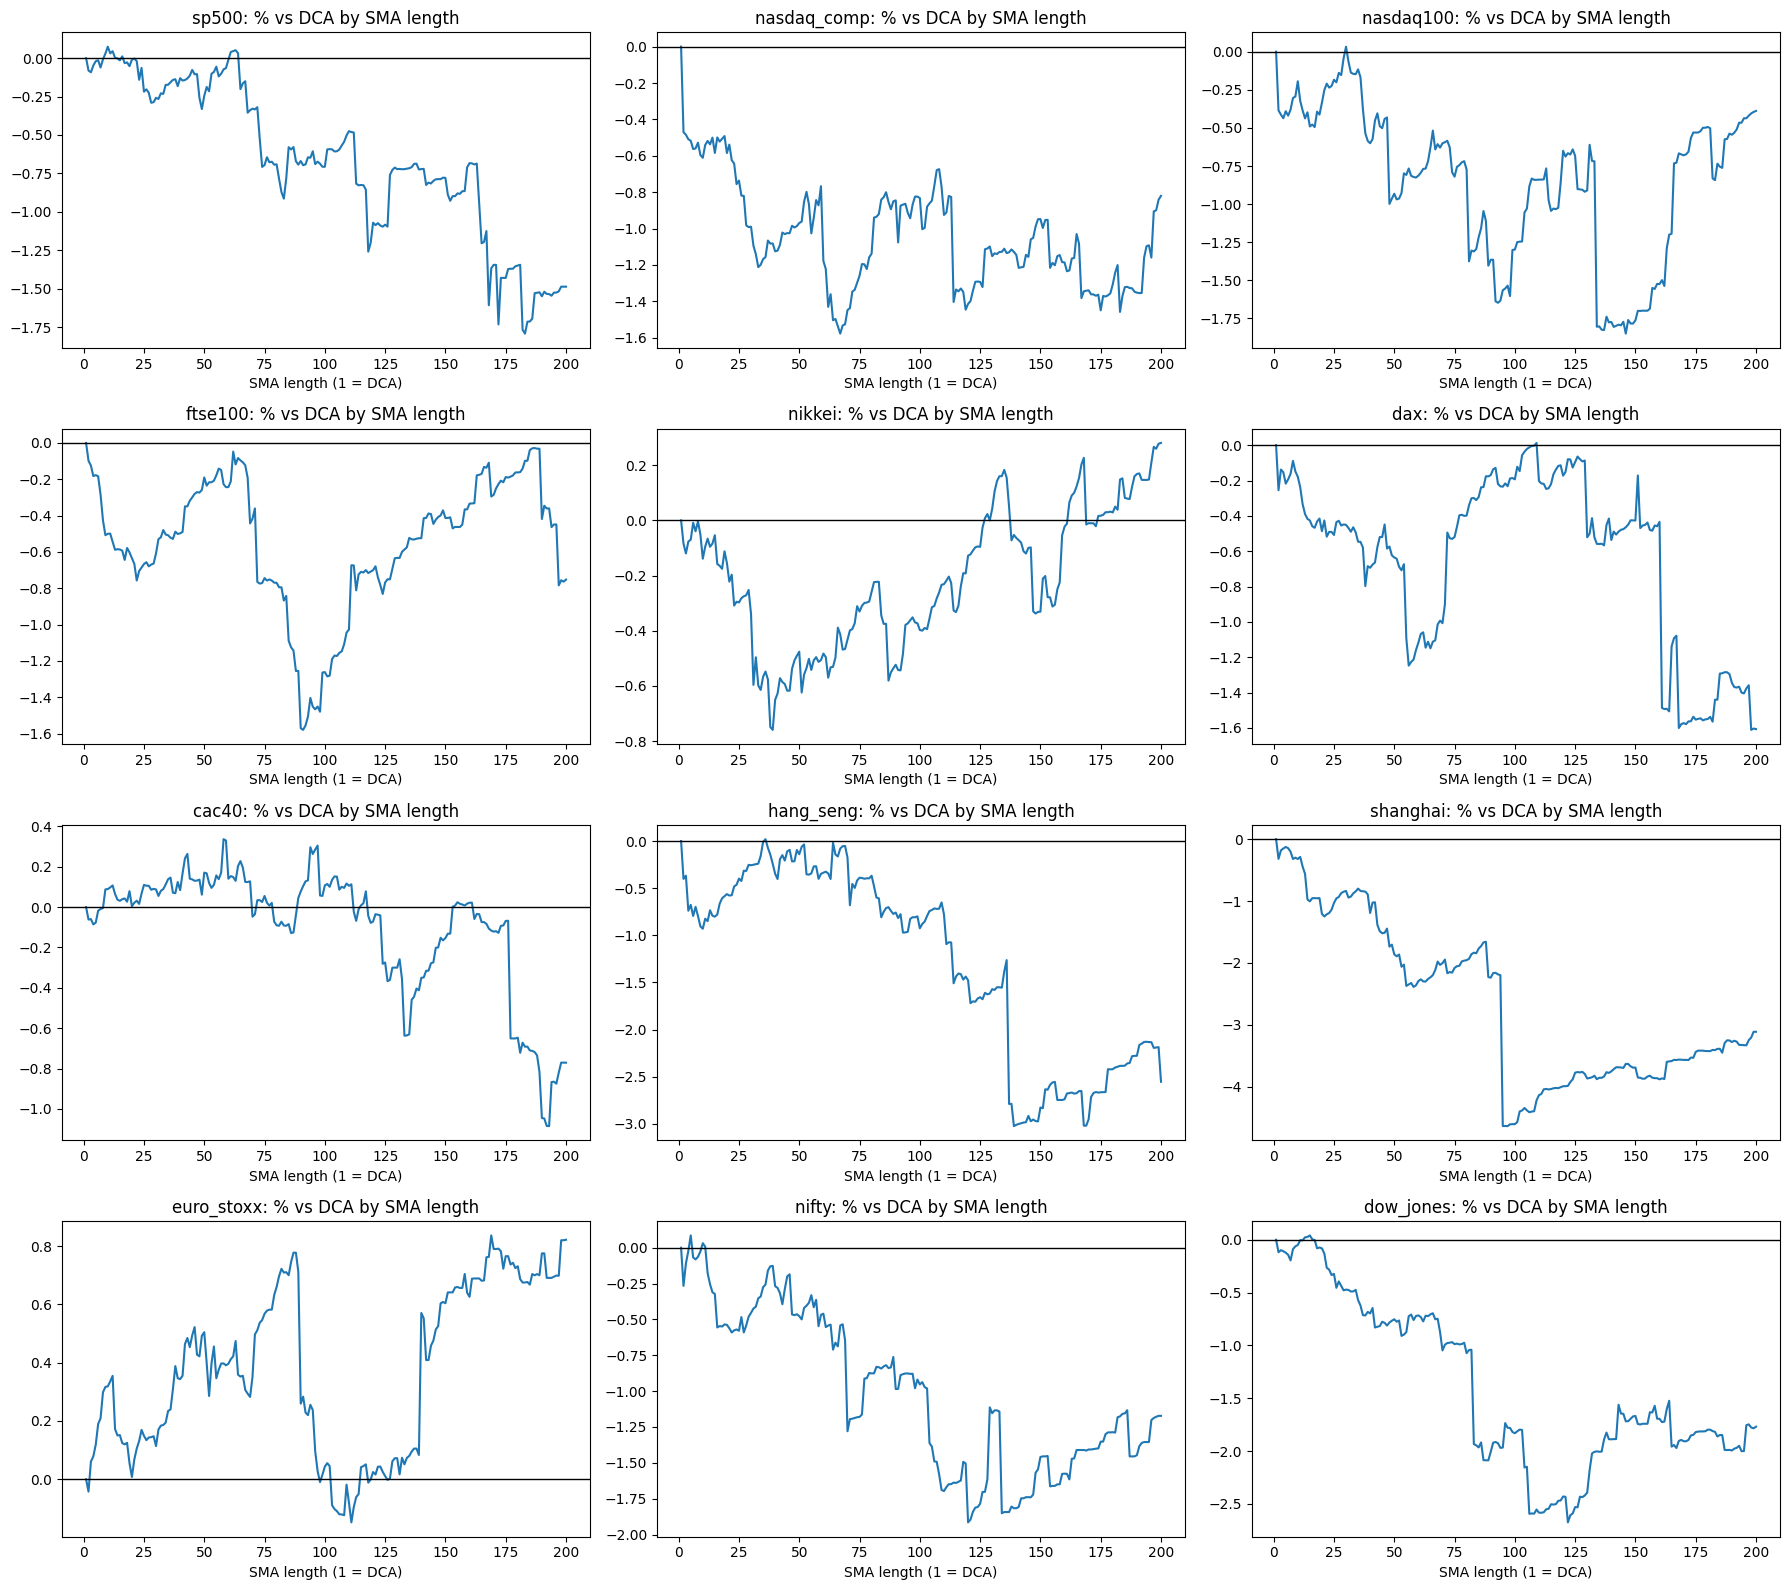

In [19]:
axes = make_grid()
for i in range(len(names)):
    ax = axes[i]
    dca = finals[names[i]][0]
    diffs = []
    for value in finals[names[i]]:
        diffs.append((value / dca - 1) * 100)
    ax.plot(x_values, diffs)
    ax.axhline(0, color="black", linewidth=1)  # above this line = beats DCA
    ax.set_title(f"{names[i]}: % vs DCA by SMA length")
    ax.set_xlabel("SMA length (1 = DCA)")
plt.tight_layout()
plt.show()

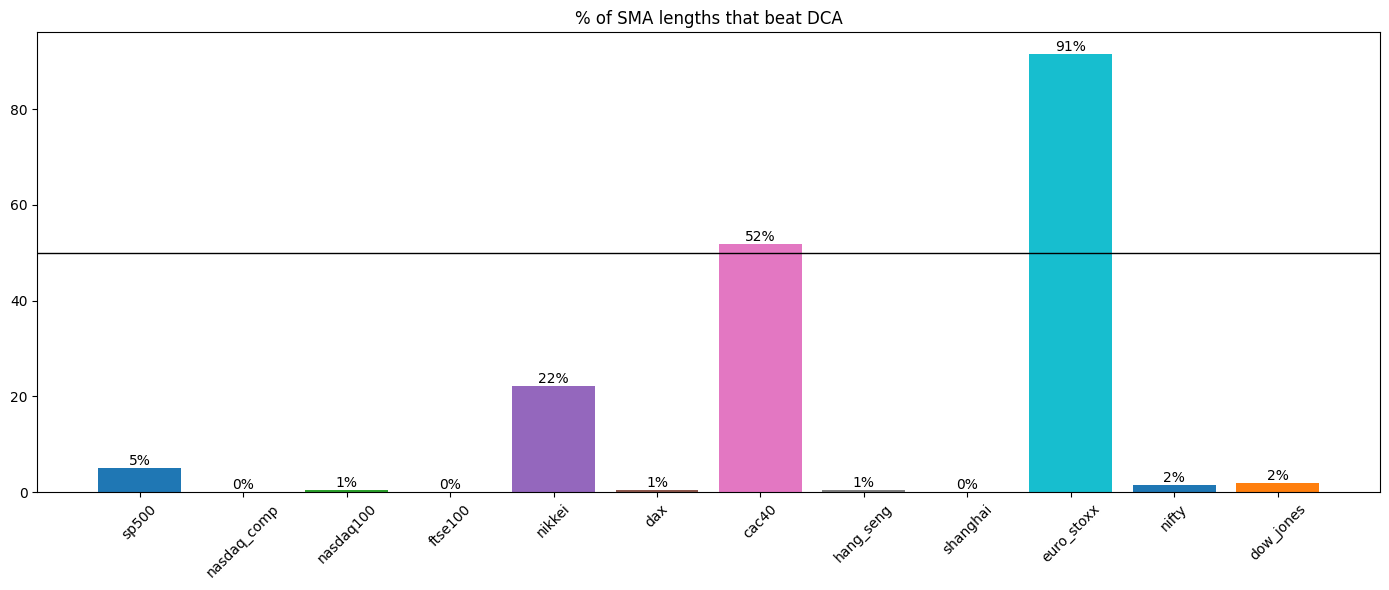

In [20]:
beat_pct = []
labels = []
for name in names:
    dca = finals[name][0]
    beat = 0
    for value in finals[name][1:]:  # skip DCA itself
        if value > dca:
            beat += 1
    pct_beat = beat / (len(finals[name]) - 1) * 100
    beat_pct.append(pct_beat)
    labels.append(f"{pct_beat:.0f}%")

fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.bar(names, beat_pct, color=colors)
ax.bar_label(bars, labels=labels)
ax.axhline(50, color="black", linewidth=1)
ax.set_title("% of SMA lengths that beat DCA")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()

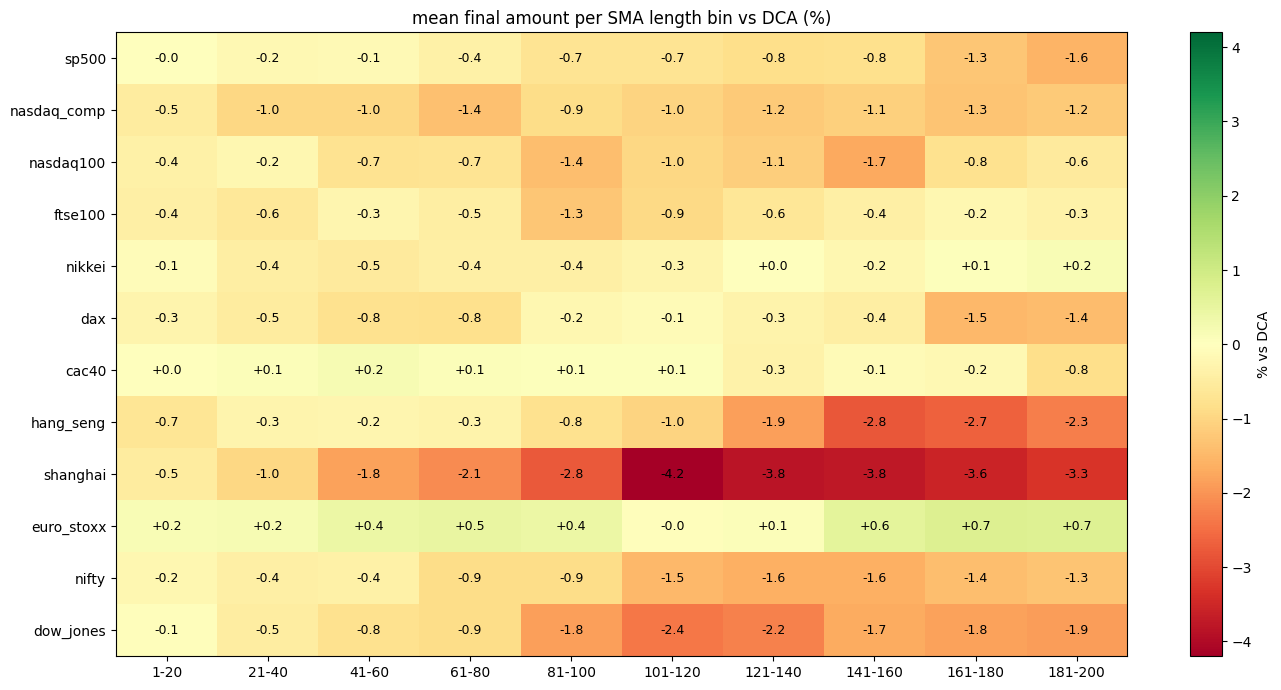

In [21]:
grid = []
for name in names:
    means = get_bin_means(finals[name])
    row = []
    for mean in means:
        row.append((mean / finals[name][0] - 1) * 100)
    grid.append(row)

biggest = 0  # symmetric color scale so 0 is the middle color
for row in grid:
    for value in row:
        if abs(value) > biggest:
            biggest = abs(value)

fig, ax = plt.subplots(figsize=(14, 7))
image = ax.imshow(grid, cmap="RdYlGn", vmin=-biggest, vmax=biggest, aspect="auto")  # green = beats DCA, red = loses
ax.set_xticks(range(len(bin_labels)))
ax.set_xticklabels(bin_labels)
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names)
for r in range(len(names)):
    for c in range(len(bin_labels)):
        ax.text(c, r, f"{grid[r][c]:+.1f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, label="% vs DCA")
ax.set_title("mean final amount per SMA length bin vs DCA (%)")
plt.tight_layout()
plt.show()

In [22]:
# ---- settings ----
BLOCK = 3                           # points hidden on each side of the test point during cross-validation
HALF_LIST = [4, 5, 8, 12, 20, 30]   # windows to try; each must be bigger than BLOCK

# ---- check the inputs ----
for name in names:
    assert len(finals[name]) == len(x_values), name   # one final amount per strategy


def average_around(values, k, half, hide):
    # Average of the points within `half` positions of point k (window shrinks at the edges).
    # Points within `hide` positions of k are skipped. hide = -1 skips nothing, so k itself counts.
    total = 0
    count = 0
    for j in range(max(0, k - half), min(len(values), k + half + 1)):
        if abs(j - k) > hide:
            total += values[j]
            count += 1
    return total / count


def cv_miss(values, half):
    # Cross-validation score of one window size (lower is better).
    # Each point is predicted from its neighbours with itself and its BLOCK closest neighbours hidden.
    # The closest neighbours are hidden because SMA 10 and 11 give nearly the same result,
    # so leaving them in would let the test cheat.
    total = 0
    for k in range(len(values)):
        miss = average_around(values, k, half, BLOCK) - values[k]
        total += miss ** 2
    return total / len(values)


rows = []
for name in names:
    values = finals[name]   # final amount of each SMA length for this stock

    # 1. the plain best SMA, no smoothing
    raw_best = x_values[values.index(max(values))]

    # 2. cross-validation picks the window size with the smallest miss
    misses = []
    for half in HALF_LIST:
        misses.append(cv_miss(values, half))
    best_half = HALF_LIST[misses.index(min(misses))]

    # 3. replace every point with the average of its window, the highest averaged point is the answer
    averaged = []
    for k in range(len(values)):
        averaged.append(average_around(values, k, best_half, -1))
    averaged_best = x_values[averaged.index(max(averaged))]

    rows.append([name, raw_best, best_half, averaged_best])

display(pd.DataFrame(rows, columns=["stock", "raw best sma", "best HALF", "averaged best sma"]))

,stock,raw best sma,best HALF,averaged best sma
0,sp500,10,4,12
1,nasdaq_comp,1,4,1
2,nasdaq100,30,4,31
3,ftse100,1,4,185
4,nikkei,200,5,200
5,dax,109,8,111
6,cac40,58,4,62
7,hang_seng,36,4,48
8,shanghai,1,4,2
9,euro_stoxx,169,4,172
